In [1]:
import pickle
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
data_path = Path("data/llama/chunk_0.pkl")

In [3]:
# Load one Llama chunk
with open(data_path, "rb") as f:
    # Adjust this access based on your exact sglang output structure
    # Assuming list of dicts similar to DeepSeek or direct object
    data = pickle.load(f) 
    # Extract tensor for one sentence: (layers, tokens, embed)
    # You might need to adjust indices based on sglang format
    hs = data[0]["meta_info"]["hidden_states"][0] 

In [5]:
# Pick a middle layer (e.g., 20)
layer_idx = 20
activations = hs[layer_idx] # Shape: (tokens, embed)
print(activations.shape)

torch.Size([45, 4096])


In [6]:
# Compute stats per channel (embedding dimension)
max_vals = activations.max(dim=0).values
min_vals = activations.min(dim=0).values
medians = activations.median(dim=0).values
means = activations.mean(dim=0)

In [7]:
# Identify outliers
spike_ratio = max_vals.abs() / (medians.abs() + 1e-6)
spikey_channels = torch.where(spike_ratio > 100)[0] # Channels where max is 100x median

In [8]:
print(f"Number of spikey channels in layer {layer_idx}: {len(spikey_channels)}")
print(f"Max value observed: {max_vals.max().item()}")
print(f"Median value range: {medians.min().item()} to {medians.max().item()}")

Number of spikey channels in layer 20: 115
Max value observed: 302.0
Median value range: -4.40625 to 4.125


In [9]:
# Norm per token
token_norms = torch.norm(activations, dim=-1)
print(token_norms)

tensor([496.0000,  20.3750,  18.3750,  19.1250,  16.6250,  16.3750,  16.3750,
         18.5000,  17.2500,  17.2500,  17.6250,  19.0000,  18.2500,  17.0000,
         18.1250,  16.7500,  19.8750,  18.8750,  19.0000,  17.5000,  19.1250,
         19.2500,  17.8750,  16.3750,  16.2500,  19.2500,  18.6250,  16.6250,
         17.1250,  16.7500,  17.6250,  17.0000,  16.8750,  17.7500,  16.3750,
         19.5000,  18.7500,  18.1250,  18.6250,  19.0000,  17.3750,  17.0000,
         15.5000,  17.6250,  16.2500], dtype=torch.bfloat16)


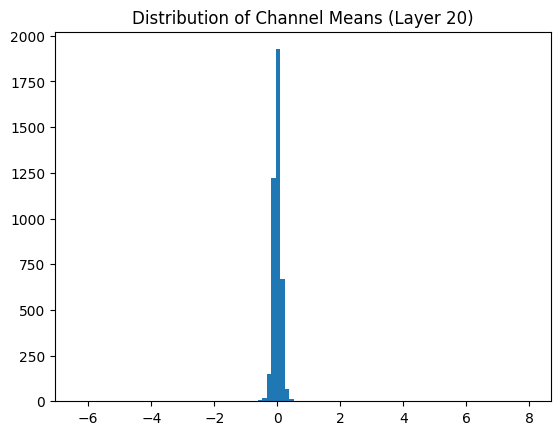

In [11]:
plt.hist(means.float().numpy(), bins=100)
plt.title("Distribution of Channel Means (Layer 20)")
plt.show()